# Week 1 — Exploratory Data Analysis (EDA)

This notebook loads the CERT r4.2 dataset (pre-aggregated `dayr4.2.csv`), performs exploratory data analysis, and builds the processed feature set that the Week 1 Random Forest baseline (and downstream tiers) consume.

Everything here is **split-agnostic**: it loads data and engineers features but does **not** fit any model or compute evaluation metrics. The canonical 60/20/20 **user-level** split lives separately in `data/user_splits/` and is consumed by `week1_random_forest_binary.ipynb`.


## 1. Setup

Resolve the project root by walking up to `pyproject.toml` (the project's portability convention), so this notebook runs from any working directory and the parent folder can be renamed freely.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Resolve project root (portability convention used across the project)
_curr = Path.cwd()
while not (_curr / 'pyproject.toml').exists() and _curr != _curr.parent:
    _curr = _curr.parent
PROJECT_ROOT = _curr
DATA_DIR = PROJECT_ROOT / 'data'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

RAW_CSV = DATA_DIR / 'dayr4.2.csv'
print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset : {RAW_CSV}")

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

Project root: C:\insider_threat_detection_project2
Raw dataset : C:\insider_threat_detection_project2\data\dayr4.2.csv


## 2. Data Loading

`dayr4.2.csv` is the pre-aggregated CERT r4.2 dataset — one row per user per day. It is large (~550 MB), so we downcast floats to `float32` (matching the Tier-1 notebooks' memory strategy).

In [2]:
# --- Load the raw day-level dataset ---
df = pd.read_csv(RAW_CSV)

# Downcast float64 -> float32 to halve memory (project convention)
for col in df.select_dtypes(include=['float64']).columns:
    df[col] = df[col].astype('float32')

print(f"Dataset shape: {df.shape}")
print(f"Users        : {df['user'].nunique()}")
print(f"Days (unique): {df['day'].nunique()}")
print(f"Weeks        : {sorted(df['week'].unique().tolist())}")
df.head(3)

Dataset shape: (330452, 508)
Users        : 1000
Days (unique): 501
Weeks        : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72]


,starttime,endtime,user,day,week,isweekday,isweekend,role,b_unit,f_unit,...,afterhourhttp_n_hackf,afterhourhttp_hackf_mean_url_len,afterhourhttp_hackf_mean_url_depth,afterhourhttp_hackf_mean_http_c_len,afterhourhttp_hackf_mean_http_c_nwords,afterhourhttp_hackf_n-pc0,afterhourhttp_hackf_n-pc1,afterhourhttp_hackf_n-pc2,afterhourhttp_hackf_n-pc3,insider
0,1.262372e+09,1.262459e+09,10,5,0,0,1,39,0,4,...,0,0,0,0,0,0,0,0,0,0
1,1.262372e+09,1.262459e+09,12,5,0,0,1,39,0,4,...,0,0,0,0,0,0,0,0,0,0
2,1.262372e+09,1.262459e+09,59,5,0,0,1,39,0,4,...,0,0,0,0,0,0,0,0,0,0


## 3. Data Inspection

### 3.1 Missing values & data types

All features are numeric; there should be no missing values.

In [3]:
print("=== Data types ===")
print(df.dtypes.value_counts())

print("\n=== Missing values ===")
nulls = df.isnull().sum()
print(f"Columns with any null: {int((nulls > 0).sum())} / {len(df.columns)}")
print(f"Total null cells: {int(nulls.sum())}")

print("\n=== Meta columns ===")
print(df[['user', 'week', 'day', 'insider']].describe().T)

=== Data types ===
int64      348
float32    160
Name: count, dtype: int64

=== Missing values ===
Columns with any null: 0 / 508
Total null cells: 0

=== Meta columns ===
            count        mean         std  min    25%    50%    75%    max
user     330452.0  503.076864  288.517424  0.0  253.0  504.0  754.0  999.0
week     330452.0   34.856094   20.553480  0.0   17.0   34.0   53.0   72.0
day      330452.0  245.975888  143.848286  5.0  121.0  241.0  372.0  505.0
insider  330452.0    0.005650    0.105793  0.0    0.0    0.0    0.0    3.0


### 3.2 Class distribution (target `insider`)

The dataset is **highly imbalanced**: the vast majority of user-days are normal, and only a handful of users are malicious. The binary framing used by the project collapses malicious scenarios (insider > 0) into a single Threat class.

In [4]:
# Target distribution (per user-day)
y_binary = (df['insider'] > 0).astype(int)
print("=== Per user-day (binary) ===")
print(y_binary.value_counts().to_string())
print(f"Threat rate: {y_binary.mean():.5f}")

# Per-user distribution
user_level = df.groupby('user')['insider'].max().astype(int)
print("\n=== Per user (binary) ===")
print((user_level > 0).astype(int).value_counts().to_string())
print(f"Malicious users: {(user_level > 0).sum()} / {len(user_level)}")

# Multilabel breakdown
print("\n=== Insider scenario labels ===")
print(df['insider'].value_counts().sort_index().to_string())

=== Per user-day (binary) ===
insider
0    329486
1       966
Threat rate: 0.00292

=== Per user (binary) ===
insider
0    930
1     70
Malicious users: 70 / 1000

=== Insider scenario labels ===
insider
0    329486
1        85
2       861
3        20


### 3.3 Behavioral modality coverage

The features are organized by behavioral modality (logon, email, http, file/device, usb) plus psychometric (OCEAN) personality features. Below we count how many feature columns belong to each group — this mirrors how Tier-1 splits channels by modality.

In [5]:
def modality_groups(cols):
    groups = {}
    for c in cols:
        low = c.lower()
        if low in ('user','week','day','insider','starttime','endtime','isweekday','isweekend'):
            g = 'meta'
        elif c in ('O','C','E','A','N'):
            g = 'personality'
        elif 'logon' in low or 'logout' in low:
            g = 'logon'
        elif 'email' in low or 'mail' in low:
            g = 'email'
        elif 'http' in low or 'url' in low:
            g = 'http'
        elif any(k in low for k in ('file','device','comp','disk','phof','docf','txtf','exef','usb')):
            g = 'file_device'
        elif 'allact' in low:
            g = 'activity'
        else:
            g = 'other'
        groups.setdefault(g, []).append(c)
    return groups

groups = modality_groups(df.columns.tolist())
print(f"{'Modality':<14} {'# features':>10}")
print('-'*26)
for g, cols in sorted(groups.items(), key=lambda kv: -len(kv[1])):
    print(f"{g:<14} {len(cols):>10}")

Modality       # features
--------------------------
file_device           228
http                  189
email                  42
activity               15
logon                  15
meta                    8
other                   6
personality             5


## 4. Exploratory Data Analysis

### 4.1 Target distribution by day & week

Check how threat activity is spread across the observation window.

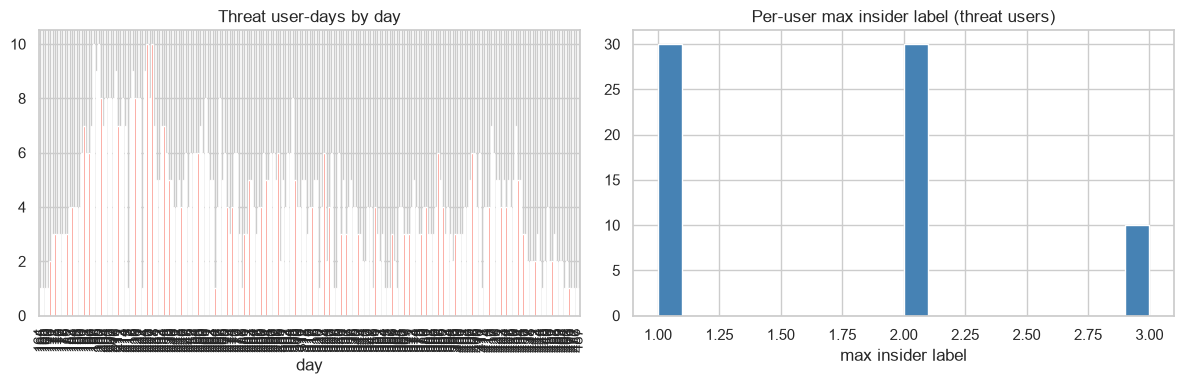

In [6]:
fig, axes = plt.subplots(1, 2)
# Threat user-days by day
threat = df[df['insider'] > 0]
ax = axes[0]
threat['day'].value_counts().sort_index().plot(kind='bar', ax=ax, color='salmon')
ax.set_title('Threat user-days by day')
ax.set_xlabel('day')

# Per-user insider load
ax = axes[1]
by_user = df.groupby('user')['insider'].max()
ax.hist(by_user[by_user > 0], bins=20, color='steelblue')
ax.set_title('Per-user max insider label (threat users)')
ax.set_xlabel('max insider label')
plt.tight_layout()
plt.show()

### 4.2 Feature distribution on a few key signals

Compare a small set of interpretable features between normal and threat user-days. (Plots are illustrative; no model decision is made here.)

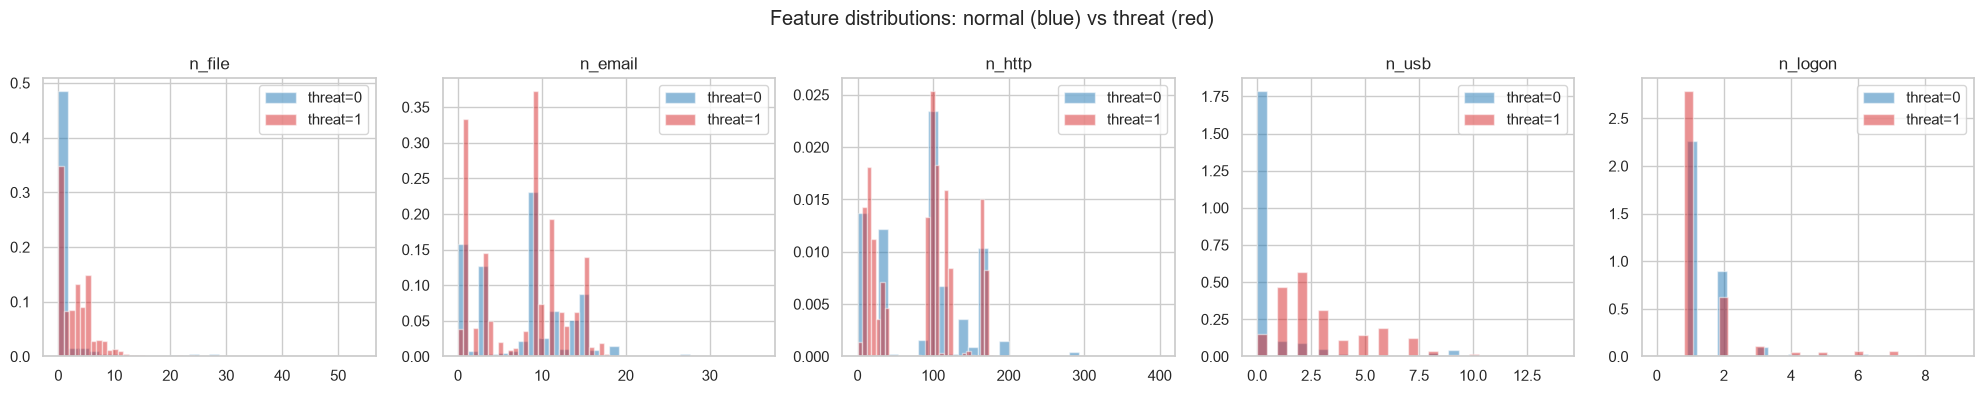

In [7]:
key_feats = ['n_file', 'n_email', 'n_http', 'n_usb', 'n_logon']
sig = df[['insider'] + key_feats].copy()
sig['binary'] = (sig['insider'] > 0).astype(int)
fig, axes = plt.subplots(1, len(key_feats), figsize=(20, 4))
for ax, f in zip(axes, key_feats):
    for lab, color in [(0, 'tab:blue'), (1, 'tab:red')]:
        subset = sig[sig['binary'] == lab][f]
        ax.hist(subset, bins=30, alpha=0.5, label=f"threat={lab}", color=color, density=True)
    ax.set_title(f"{f}")
    ax.legend()
plt.suptitle('Feature distributions: normal (blue) vs threat (red)')
plt.tight_layout()
plt.show()

### 4.3 Correlation with the target

Rank features by absolute correlation with the (binary) threat label. This is a quick screen to highlight which modality signals are most associated with insider activity.

C:\insider_threat_detection_project2\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\insider_threat_detection_project2\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Top 15 features by |corr| with binary threat label:
http_leakf_mean_url_depth                 0.264957
http_leakf_mean_url_len                   0.264957
http_n_leakf                              0.263111
afterhourhttp_leakf_mean_url_depth        0.261030
afterhourhttp_leakf_mean_url_len          0.261030
http_leakf_mean_http_c_nwords             0.260167
http_leakf_mean_http_c_len                0.259871
afterhourhttp_n_leakf                     0.259160
http_leakf_n-pc0                          0.259160
afterhourhttp_leakf_mean_http_c_nwords    0.256652
afterhourhttp_leakf_mean_http_c_len       0.256374
afterhourhttp_leakf_n-pc0                 0.255149
usb_mean_usb_dur                          0.109749
workhourhttp_hackf_mean_url_len           0.101284
http_hackf_mean_url_len                   0.101284


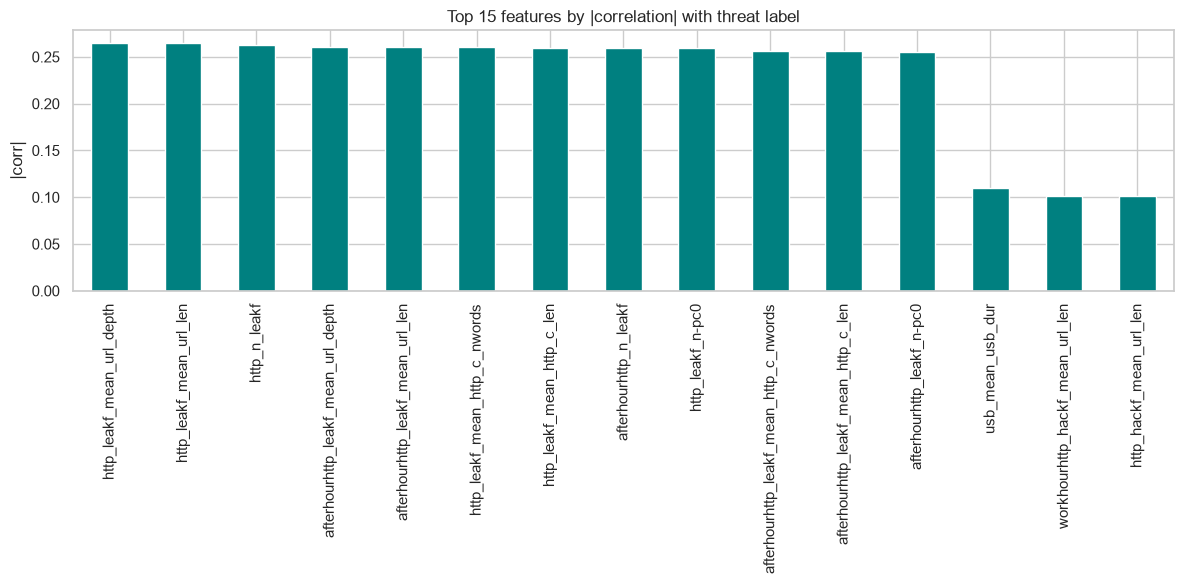

In [8]:
X = df.drop(columns=['insider'])
y = (df['insider'] > 0).astype(int)
corr = X.corrwith(y).abs().sort_values(ascending=False)
print("Top 15 features by |corr| with binary threat label:")
print(corr.head(15).to_string())
plt.figure(figsize=(12, 6))
corr.head(15).plot(kind='bar', color='teal')
plt.title('Top 15 features by |correlation| with threat label')
plt.ylabel('|corr|')
plt.tight_layout()
plt.show()

## 5. Feature Engineering

The raw dataset is already highly engineered (aggregate counts, percentiles, means per modality). Here we keep the design **identical to the existing Week-1 baseline**: drop non-predictive meta/timestamp columns, retain `user` for the downstream split, binarize `insider`, and produce a clean numeric feature matrix. No new synthetic features are invented so results remain comparable to prior runs.

In [9]:
X = df.copy()

# --- Drop non-predictive meta/timestamp columns, but KEEP 'user' for splitting ---
drop_cols = ['starttime', 'endtime', 'day', 'week']
X = X.drop(columns=[c for c in drop_cols if c in X.columns])

# --- Binarize target ---
X['insider'] = (X['insider'] > 0).astype(int)

# --- Separate features from target (features exclude 'insider') ---
feature_cols = [c for c in X.columns if c != 'insider' and c != 'user']
X_features = X[feature_cols].copy()

print(f"Cleaned dataset shape: {X.shape}")
print(f"Feature count (excl. user/insider): {len(feature_cols)}")
print(f"Target distribution: {X['insider'].value_counts().to_dict()}")

Cleaned dataset shape: (330452, 504)
Feature count (excl. user/insider): 502
Target distribution: {0: 329486, 1: 966}


## 6. Save Processed Features

Save the clean feature matrix (with `user` retained for splitting and `insider` as the binary target) to Parquet for fast, deterministic reload by the Random Forest notebook and future tiers. Also save the feature column list.

In [10]:
# --- Save processed features (Parquet, project's fast columnar format) ---
X.to_parquet(PROCESSED_DIR / 'features_clean.parquet', index=False)
print(f"Saved processed features: {PROCESSED_DIR / 'features_clean.parquet'}")

# Save feature column list for reference
feat_cols = pd.DataFrame({'feature_col': feature_cols})
feat_cols.to_csv(PROCESSED_DIR / 'feature_columns.csv', index=False)

print(f"features_clean.parquet: {X.shape}")
print(f"feature_columns.csv   : {len(feature_cols)} columns")

Saved processed features: C:\insider_threat_detection_project2\data\processed\features_clean.parquet
features_clean.parquet: (330452, 504)
feature_columns.csv   : 502 columns


## 7. Summary

* Loaded `dayr4.2.csv` (pre-aggregated CERT r4.2, one row per user/day).
* Inspected dtypes, missing values, and class distributions (highly imbalanced; 70 malicious users overall).
* EDA: threat spread over days, feature distributions, and correlation screening.
* Engineered a clean numeric feature set (binarized `insider`; `user` retained for splitting; non-predictive meta dropped) — matching the existing Week-1 protocol.
* Saved processed features to `data/processed/features_clean.parquet` + `data/processed/feature_columns.csv`.
* The **canonical user split** is stored separately in `data/user_splits/` and is loaded by `week1_random_forest_binary.ipynb` — EDA does not perform any split.